## Ejercicio 9

In [15]:
import numpy as np
import matplotlib.pyplot as plt
import scipy

In [16]:
X_fantoma = np.array([
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.8, 0.3, 0.3, 0.3, 0.0, 0.0],
    [0.0, 0.8, 0.8, 0.8, 0.3, 0.3, 0.3, 0.0],
    [0.0, 0.3, 0.8, 0.3, 0.3, 0.3, 0.3, 0.0],
    [0.0, 0.3, 0.3, 0.3, 0.3, 0.5, 0.3, 0.0],
    [0.0, 0.3, 0.3, 0.3, 0.5, 0.5, 0.5, 0.0],
    [0.0, 0.0, 0.3, 0.3, 0.3, 0.5, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
], dtype=float)

n = X_fantoma.shape[0]
x_fantoma = X_fantoma.reshape(-1)

In [17]:
def mascara_rayo(n, direccion, s):
    alfa = direccion[0]
    beta = direccion[1]
    matriz = np.zeros((n, n), dtype=int)
    for i in range(n):
        for j in range(n):
            if alfa * i + beta * j == s:
                matriz[i][j] = 1
    return matriz


def matriz_proyeccion(n, direcciones):
    filas_A = []
    rayos = []

    for direccion in direcciones:
        alfa = direccion[0]
        beta = direccion[1]
        valores_s = set()

        for i in range(n):
            for j in range(n):
                valores_s.add(alfa * i + beta * j)

        for s in sorted(valores_s):
            mascara = mascara_rayo(n, direccion, s)
            filas_A.append(mascara.reshape(-1))
            rayos.append((direccion, s))

    A = np.array(filas_A, dtype=float)
    return A, rayos

In [18]:
D2 = [(1, 0), (0, 1)]
D4 = D2 + [(1, 1), (1, -1)]
D7 = D4 + [(2, 1), (1, 2), (3, 1)]

A2, rayos2 = matriz_proyeccion(n, D2)
A4, rayos4 = matriz_proyeccion(n, D4)
A7, rayos7 = matriz_proyeccion(n, D7)

### Inciso a)

In [19]:
def matriz_diferencias(n):
    # Guardamos por separado las diferencias entre vecinos horizontales y verticales
    filas_h = []
    filas_v = []

    # k es la posición del píxel (i, j) en el vector de la imagen
    # El -1 y el 1 permiten restarle ese píxel a su vecino de la derecha
    for i in range(n):
        for j in range(n - 1):
            k = i * n + j
            fila = np.zeros(n**2)
            fila[k] = -1
            fila[k + 1] = 1
            filas_h.append(fila)

    # Repetimos el procedimiento con el vecino de abajo, ubicado en k + n
    for i in range(n - 1):
        for j in range(n):
            k = i * n + j
            fila = np.zeros(n**2)
            fila[k] = -1
            fila[k + n] = 1
            filas_v.append(fila)

    # Unimos ambas listas: primero las diferencias horizontales y después las verticales
    return np.array(filas_h + filas_v, dtype=float)


In [20]:
# Construimos D y comprobamos que cada fila compare solamente dos píxeles
# axis=1 indica que contamos los valores en cada fila de la matriz
D = matriz_diferencias(n)
print("Dimensiones de D:", D.shape)
print("¿Cada fila tiene un -1?", np.all(np.sum(D == -1, axis=1) == 1))
print("¿Cada fila tiene un 1?", np.all(np.sum(D == 1, axis=1) == 1))

# Los assert verifican las dimensiones y la cantidad de valores no nulos por fila
assert D.shape == (112, 64)
assert np.all(np.sum(D == -1, axis=1) == 1)
assert np.all(np.sum(D == 1, axis=1) == 1)
assert np.all(np.count_nonzero(D, axis=1) == 2)

# Verificamos que D @ x_fantoma coincida con las diferencias calculadas con np.diff
# Las primeras 56 son horizontales (axis=1) y las últimas 56, verticales (axis=0)
Dx = D @ x_fantoma
assert np.allclose(Dx[:n*(n-1)], np.diff(X_fantoma, axis=1).reshape(-1))
assert np.allclose(Dx[n*(n-1):], np.diff(X_fantoma, axis=0).reshape(-1))


Dimensiones de D: (112, 64)
¿Cada fila tiene un -1? True
¿Cada fila tiene un 1? True


### Inciso b)

In [21]:
# Creamos una imagen constante con todos los píxeles con valor 1
x_constante = np.ones(n**2)

# Comparamos las diferencias entre vecinos: 
# en la imagen constante debería ser cero, ya que no hay diferencias entre los píxeles
# En el fantoma la norma es positiva porque hay cambios entre algunos píxeles
print("Norma de D @ x_constante:", np.linalg.norm(D @ x_constante))
print("Norma de D @ x_fantoma:", np.linalg.norm(D @ x_fantoma))
assert np.allclose(D @ x_constante, 0)


Norma de D @ x_constante: 0.0
Norma de D @ x_fantoma: 2.7055498516937364


En una imagen constante, todos los vecinos tienen el mismo valor, ya que cada fila de $D$ resta
dos valores iguales y todas las diferencias son cero. <br> En cambio, en el fantoma, tiene bordes y
cambios de atenuación y por eso su norma de diferencias es aproximadamente $2,706$.

### Inciso c)

El costo que queremos minimizar es:

$$J_{\sigma,\lambda}(x)=\frac12\|A_7x-b_\sigma\|^2+\frac{\lambda}{2}\|Dx\|^2.$$

El primer término mide qué tan bien se ajusta la reconstrucción a las mediciones observadas. El segundo penaliza las diferencias entre píxeles vecinos, favoreciendo imágenes más suaves.

Además, la norma de las diferencias al cuadrado $(\|Dx\|^2)$ se puede expresar como:

$$\|Dx\|^2=\sum_{i=0}^{n-1}\sum_{j=0}^{n-2}(X_{i,j+1}-X_{ij})^2+\sum_{i=0}^{n-2}\sum_{j=0}^{n-1}(X_{i+1,j}-X_{ij})^2.$$

El primer término (doble sumatoria) suma las diferencias al cuadrado entre pares de píxeles vecinos de una misma fila. El segundo término hace lo mismo pero con las columnas.
<br> <br> En total, la expresión $\|Dx\|^2$ suma los cuadrados de las diferencias entre píxeles vecinos, tanto horizontal como verticalmente. Si los valores de los píxeles vecinos son parecidos, estas diferencias son pequeñas y la norma también. En cambio, si hay cambios grandes entre píxeles cercanos, la norma aumenta. 
<br> <br> Por lo tanto, esta expresión mide cuánto varía la imagen entre píxeles vecinos, y no los valores de los píxeles por separado. Por ejemplo, si sumamos una misma constante a todos los píxeles, las diferencias entre ellos siguen siendo las mismas.

El parámetro $\lambda$ determina la importancia que le damos a la regularización. Si $\lambda = 0$ , sólo buscamos ajustar las mediciones como en mínimos cuadrados. A medida que aumenta $\lambda$, se penalizan más las variaciones entre píxeles vecinos, lo que puede ayudar a reducir el ruido. Sin embargo, si la regularización es demasiado fuerte, también puede suavizar o borrar bordes y detalles reales de la imagen.

### Inciso d)

In [22]:
# Calculamos las mediciones sin ruido a partir del fantoma
b7 = A7 @ x_fantoma

# Utilizamos de nuevo la semilla 67 para repetir el mismo ruido que usamos en el ejercicio 6 y generamos un vector z aleatorio
rng = np.random.default_rng(67)
z = rng.standard_normal(b7.size)

# Esta escala adapta la intensidad del ruido al tamaño de las mediciones
escala = np.sqrt(np.mean(b7**2))


In [23]:
# Creamos los vectores sigma y lambda que contienen los valores del nivel de ruido y el peso de la regularización, respectivamente
sigmas = [0.0, 0.10, 0.20]
lambdas = [0.0, 0.1, 0.3, 1.0]

# Guardamos las mediciones de cada sigma en un diccionario
# Usamos el mismo vector z y variamos la intensidad del ruido según sigma
mediciones = {sigma: b7 + sigma * escala * z for sigma in sigmas}

# Para asegurarnos que se generaron correctamente las mediciones:
# Muestra las dimensiones de las mediciones para cada sigma (=119)
for sigma in sigmas:
    print(f"sigma = {sigma}: {mediciones[sigma].shape}")

sigma = 0.0: (119,)
sigma = 0.1: (119,)
sigma = 0.2: (119,)


### Inciso e)

In [24]:
def gradiente_descendiente(A, b, alfa, max_iter=10000, tol=1e-8,
                          D=None, lam=0.0, x_ref=None):
    # Empezamos con una imagen de ceros 
    # Inicializamos las variables A_T y D_T (si no es none)
    x = np.zeros(A.shape[1], dtype=float)
    A_T = A.T
    D_T = None if D is None else D.T

    # Preparamos los historiales y los datos que usaremos para decidir cuándo parar
    costos = []
    normas_gradiente = []
    errores = []
    norma_inicial = None
    motivo = "máximo de iteraciones"

    t = 0
    for t in range(max_iter + 1):
        # Calculamos el costo y el gradiente del ajuste a las mediciones
        residuo = A @ x - b
        costo = 0.5 * np.dot(residuo, residuo)
        grad = A_T @ residuo

        # Agregamos regularización solo si tenemos D (no es None) y su peso no es cero
        if D is not None and lam != 0:
            diferencias = D @ x
            costo += 0.5 * lam * np.dot(diferencias, diferencias)
            grad = grad + lam * (D_T @ diferencias)

        norma_grad = np.linalg.norm(grad)

        # Guardamos la norma inicial solo en la primera vuelta
        if norma_inicial is None:
            norma_inicial = norma_grad

        # Registramos el costo y la norma del gradiente antes de actualizar la imagen
        costos.append(float(costo))
        normas_gradiente.append(float(norma_grad))

        # Si conocemos el fantoma, registramos el error relativo para comparaciones
        if x_ref is not None:
            errores.append(np.linalg.norm(x - x_ref) / np.linalg.norm(x_ref))

        # Frenamos si el costo es infinito o supera un límite muy grande (Usamos como tope límite 1e25)
        if not np.isfinite(costo) or costo > 1e25:
            motivo = "costo divergente"
            break

        # Paramos cuando el gradiente es pequeño respecto de su norma inicial
        # max(1.0, norma_inicial) evita exigir una tolerancia menor que tol si esa norma es menor que 1
        if norma_grad <= tol * max(1.0, norma_inicial):
            motivo = "tolerancia del gradiente"
            break

        # Al llegar al máximo de iteraciones, salimos del ciclo
        if t == max_iter:
            break

        # Actualizamos la imagen en la dirección opuesta al gradiente
        x = x - alfa * grad

    # Devolvemos la reconstrucción, los historiales y el motivo de parada
    return {"x": x, "costos": np.array(costos),
            "normas_gradiente": np.array(normas_gradiente),
            "errores": np.array(errores), "iteraciones": t, "motivo": motivo}


Reutilizamos la función de gradiente y la adaptamos para incluir la regularización. Para ello, agregamos el término $\lambda D^TDx$ al gradiente y el término $\frac{\lambda}{2}|Dx|^2$ a la función de costo. La función siempre comienza con $x_0=0$. 
<br> Además, el argumento *x_ref* permite registrar el error respecto del fantoma para los gráficos.

### Inciso f)

Tasa común elegida: 0.04934652837164658
Límite más restrictivo: 0.0548294759684962
Tolerancia relativa del gradiente: 1e-9; máximo: 10000 iteraciones



| sigma | lambda | Iteraciones | Motivo de parada |
| --- | --- | --- | --- |
| 0.0 | 0.0 | 522 | tolerancia del gradiente |
| 0.0 | 0.1 | 335 | tolerancia del gradiente |
| 0.0 | 0.3 | 199 | tolerancia del gradiente |
| 0.0 | 1.0 | 94 | tolerancia del gradiente |
| 0.1 | 0.0 | 549 | tolerancia del gradiente |
| 0.1 | 0.1 | 354 | tolerancia del gradiente |
| 0.1 | 0.3 | 212 | tolerancia del gradiente |
| 0.1 | 1.0 | 96 | tolerancia del gradiente |
| 0.2 | 0.0 | 565 | tolerancia del gradiente |
| 0.2 | 0.1 | 364 | tolerancia del gradiente |
| 0.2 | 0.3 | 219 | tolerancia del gradiente |
| 0.2 | 1.0 | 98 | tolerancia del gradiente |


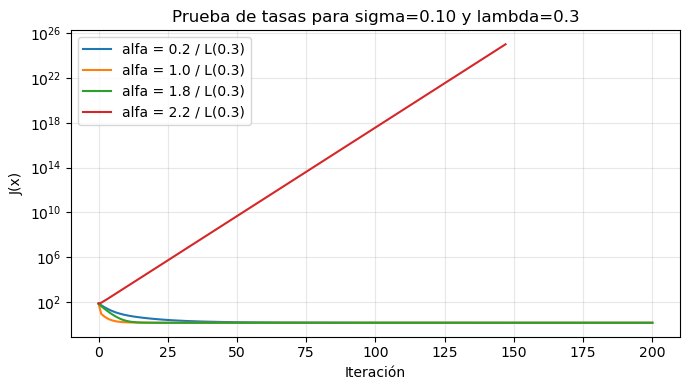

In [25]:
from IPython.display import Markdown, display

# Inicializamos H y DtD como el producto de A por su traspuesta y con D lo mismo
H = A7.T @ A7
DtD = D.T @ D
L_por_lambda = {} # Estos valores propios (máximos) (L) vamos a guardarlos para luego elegir una tasa de aprendizaje estable

for lam in lambdas:
    H_lambda = H + lam * DtD    # Construimos la Hessiana, dado el lambda
    valores_propios = np.linalg.eigvalsh(H_lambda)
    L_por_lambda[lam] = valores_propios[-1] # Tomamos el mayor valor propio

L_max = max(L_por_lambda.values())  # Tomamos el máximo entre todos los L

# Elegimos una tasa común menor que 2/L_max, que sea estable siempre = 1.8 / L_max
alfa = 1.8/L_max
print("Tasa común elegida:", alfa)
print("Límite más restrictivo:", 2/L_max)
print("Tolerancia relativa del gradiente: 1e-9; máximo: 10000 iteraciones")
print()

# Armamos una tabla que indique para cada combinación de sigma y lambda, los resultados de aplicar el método de gradiente descendiente
tabla = "| sigma | lambda | Iteraciones | Motivo de parada |\n"
tabla += "| --- | --- | --- | --- |\n"
resultados = {}
for sigma in sigmas:
    for lam in lambdas:
        resultado = gradiente_descendiente(A7, mediciones[sigma], alfa,
                                           max_iter=10000, tol=1e-9,
                                           D=D, lam=lam, x_ref=x_fantoma)
        resultados[sigma, lam] = resultado      # Además guardamos cada resultado con la clave (sigma, lam) para más adelante

        # Agregamos una fila a la tabla con los resultados de dicha combinación. Los resultados que incluimos son la cantidad de iteraciones 
        # y el motivo de parada, ya que queremos observar el comportamiento de la tasa de aprendizaje 
        tabla += "| " + str(sigma) + " | " + str(lam) + " | "
        tabla += str(resultado["iteraciones"]) + " | " + resultado["motivo"] + " |\n"

# Mostramos la tabla con los resultados de todas las combinaciones
display(Markdown(tabla))
print()

# Vamos a graficar cómo evolucionan las variables costo y cantidad de iteraciones con las distintas tasas de aprendizaje para valores fijos sigma=0.10 y lambda=0.3
factores = [0.2, 1.0, 1.8, 2.2]
fig, ax = plt.subplots(figsize=(7, 4))

for factor in factores:
    tasa = factor/L_por_lambda[0.3]
    prueba = gradiente_descendiente(A7, mediciones[0.1], tasa,
                                    max_iter=200, tol=1e-9, D=D, lam=0.3)       # Usamos como máximas iteraciones 200
    etiqueta = "alfa = " + str(factor) + " / L(0.3)"
    ax.semilogy(prueba["costos"], label=etiqueta)

ax.set_xlabel("Iteración")
ax.set_ylabel("J(x)")   # J(x) es el costo
ax.set_title("Prueba de tasas para sigma=0.10 y lambda=0.3")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

La Hessiana está definida como $A_7^TA_7+\lambda D^TD$. Calculamos su mayor autovalor $L(\lambda)$ para luego elegir una
tasa que sea menor que $2/L(\lambda)$ y que resulte estable en todos los casos. La prueba que hicimos con $2{,}2/L(0{,}3)$ muestra que se volvió inestable, ya que está fuera del intervalo y su costo dispara hacia infinito.

Por eso la parada exige que $\|\nabla J(x_t)\|$  (la norma del gradiente en la iteración $t$) sea menor o igual que $10^{-9}\max(1,\|\nabla J(x_0)\|)$ o alcanzar
el máximo de iteraciones.

### Inciso g)

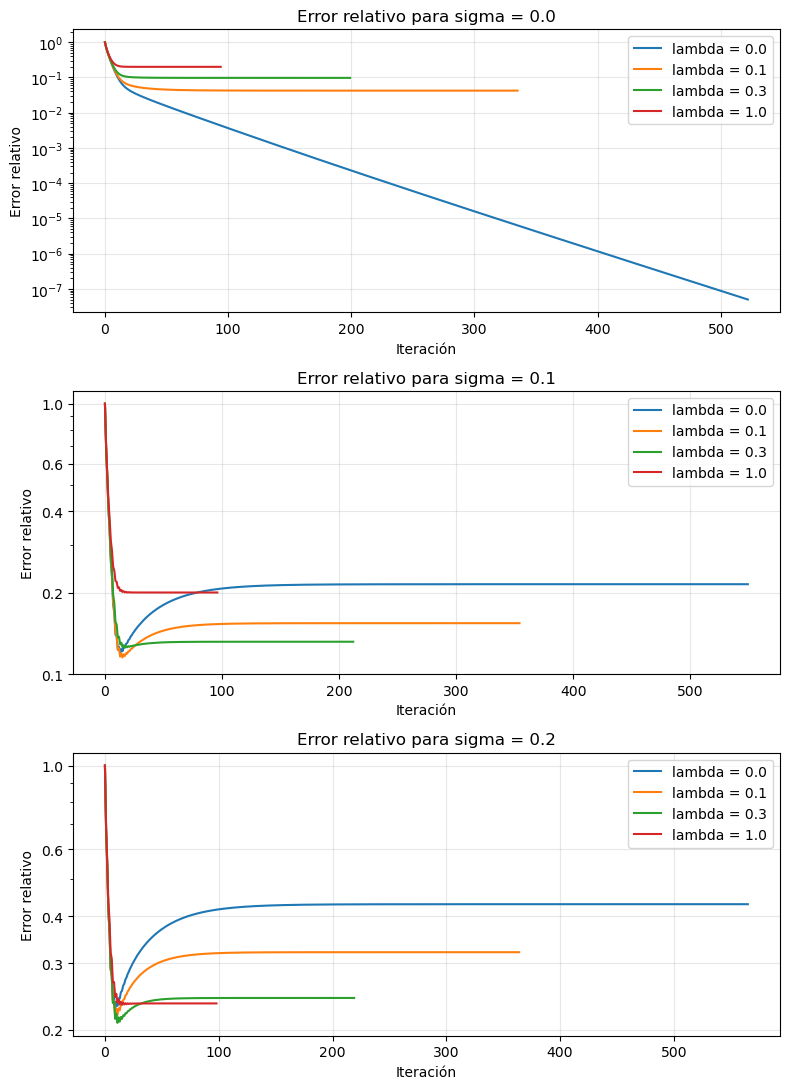

In [26]:
# Creamos un gráfico por nivel de ruido
fig, axs = plt.subplots(len(sigmas), 1, figsize=(8, 11),)

for i in range(len(sigmas)):
    sigma = sigmas[i]

    # Comparamos cómo cambia el error relativo para cada valor de lambda
    for lam in lambdas:
        errores = resultados[sigma, lam]["errores"]
        etiqueta = "lambda = " + str(lam)
        axs[i].semilogy(errores, label=etiqueta)

    # En el segundo gráfico indicamos más valores para leer mejor el eje logarítmico
    if i == 1:
        axs[i].set_yticks([0.1, 0.2, 0.4, 0.6, 1.0])
        axs[i].set_yticklabels(["0.1", "0.2", "0.4", "0.6", "1.0"])

    # En el tercer gráfico mostramos las marcas como números decimales
    if i == 2:
        axs[i].set_yticks([0.2, 0.3, 0.4, 0.6, 1.0])
        axs[i].set_yticklabels(["0.2", "0.3", "0.4", "0.6", "1.0"])

    # Agregamos el nivel de ruido, los nombres de los ejes y la leyenda
    axs[i].set_title("Error relativo para sigma = " + str(sigma))
    axs[i].set_xlabel("Iteración")
    axs[i].set_ylabel("Error relativo")
    axs[i].legend()
    axs[i].grid(alpha=0.3)

plt.tight_layout()
plt.show()


### Inciso h)

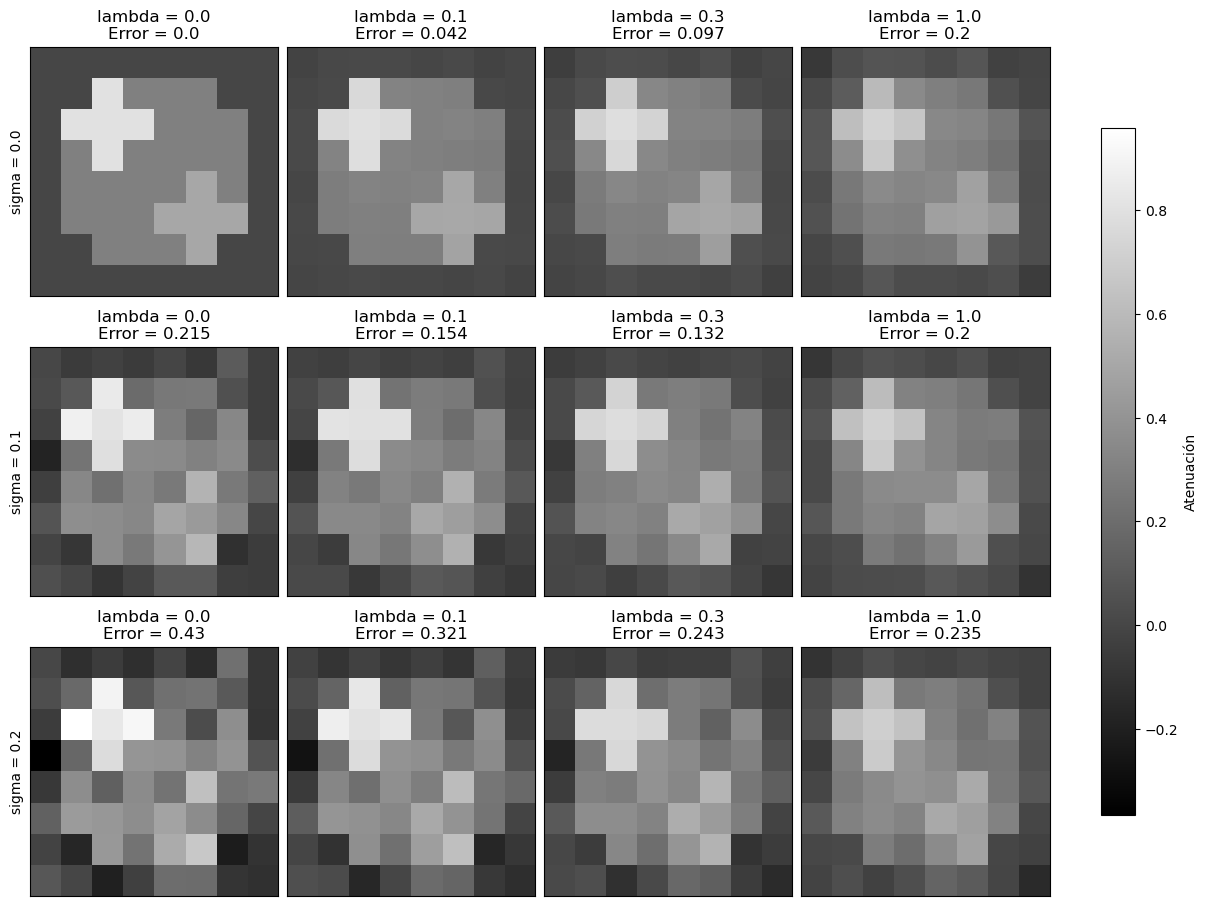

In [27]:
# Buscamos el menor y el mayor valor para usar la misma escala de grises en todas las imágenes
vmin = 0.0
vmax = np.max(X_fantoma)

for sigma in sigmas:
    for lam in lambdas:
        x = resultados[sigma, lam]["x"]
        vmin = min(vmin, np.min(x))
        vmax = max(vmax, np.max(x))

# Cada fila corresponde a un nivel de ruido y cada columna a un valor de lambda
fig, axs = plt.subplots(len(sigmas), len(lambdas), figsize=(12, 9), layout="constrained")

for i in range(len(sigmas)):
    sigma = sigmas[i]
    for j in range(len(lambdas)):
        lam = lambdas[j]

        # Recuperamos la reconstrucción y el último error relativo guardado
        resultado = resultados[sigma, lam]
        imagen = resultado["x"].reshape(n, n)
        error = resultado["errores"][-1]

        # Mostramos la imagen e indicamos lambda y el error redondeado a tres decimales
        axs[i, j].imshow(imagen, cmap="gray", vmin=vmin, vmax=vmax)
        titulo = "lambda = " + str(lam) + "\nError = " + str(round(error, 3))
        axs[i, j].set_title(titulo)
        axs[i, j].set_xticks([])
        axs[i, j].set_yticks([])

        # Escribimos sigma solo en la primera columna 
        if j == 0:
            axs[i, j].set_ylabel("sigma = " + str(sigma))

# Agregamos una barra de color común
fig.colorbar(axs[0, 0].images[0], ax=axs, label="Atenuación", shrink=0.8)
plt.show()


### Inciso i)

sigma: 0.0 / Mejor lambda: 0.0
Error relativo: 5.011173978091994e-08

sigma: 0.1 / Mejor lambda: 0.3
Error relativo: 0.1316857810081075

sigma: 0.2 / Mejor lambda: 1.0
Error relativo: 0.23496623058385757



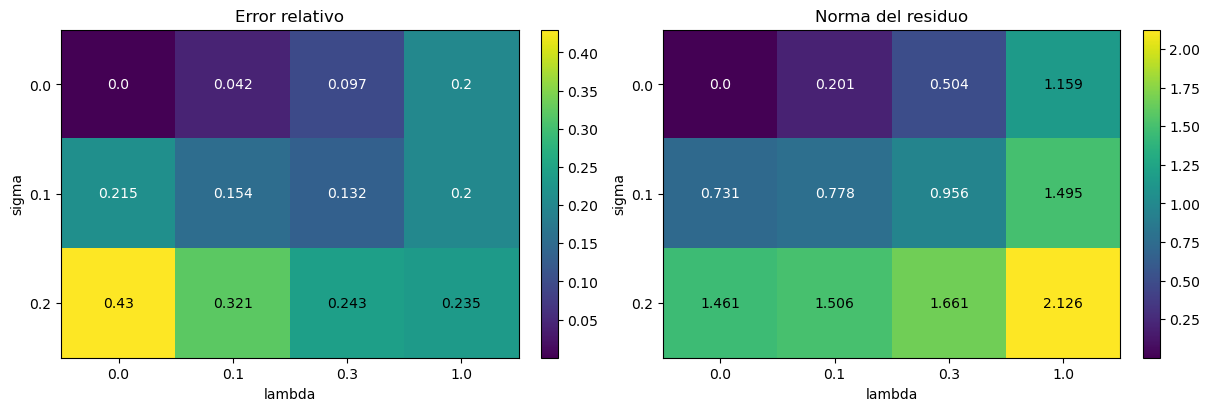

In [28]:
# Preparamos dos matrices: las filas representan sigma y las columnas, lambda
errores_finales = np.zeros((len(sigmas), len(lambdas)))
residuos_finales = np.zeros((len(sigmas), len(lambdas)))
mejores = {}

for i in range(len(sigmas)):
    sigma = sigmas[i]
    for j in range(len(lambdas)):
        lam = lambdas[j]
        x = resultados[sigma, lam]["x"]

        # El error compara la reconstrucción con el fantoma
        # El residuo compara las mediciones que produce esa imagen con las observadas
        errores_finales[i, j] = np.linalg.norm(x - x_fantoma) / np.linalg.norm(x_fantoma)
        residuos_finales[i, j] = np.linalg.norm(A7 @ x - mediciones[sigma])

    # argmin devuelve la posición del menor error de esta fila
    # Así elegimos el mejor lambda entre los valores que probamos para este sigma
    indice = np.argmin(errores_finales[i])
    mejores[sigma] = lambdas[indice]
    print("sigma:", sigma, "/ Mejor lambda:", mejores[sigma])
    print("Error relativo:", errores_finales[i, indice])
    print()

# Mostramos los errores y los residuos en dos cuadros de colores
tablas = [errores_finales, residuos_finales]
titulos = ["Error relativo", "Norma del residuo"]
fig, axs = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")

for k in range(2):
    tabla = tablas[k]
    ax = axs[k]
    imagen = ax.imshow(tabla, cmap="viridis", aspect="auto")

    # Identificamos cada columna por su lambda y cada fila por su sigma
    ax.set_xticks(range(len(lambdas)))
    ax.set_xticklabels(lambdas)
    ax.set_yticks(range(len(sigmas)))
    ax.set_yticklabels(sigmas)
    ax.set_xlabel("lambda")
    ax.set_ylabel("sigma")
    ax.set_title(titulos[k])

    # Escribimos los valores dentro de cada casillero, redondeados a tres decimales
    # Elegimos texto blanco en los colores oscuros y negro en los claros para que se lea
    punto_medio = (np.max(tabla) + np.min(tabla)) / 2
    for i in range(len(sigmas)):
        for j in range(len(lambdas)):
            if tabla[i, j] < punto_medio:
                color = "white"
            else:
                color = "black"
            valor = str(round(tabla[i, j], 3))
            ax.text(j, i, valor, ha="center", va="center", color=color)

    # Cada cuadro tiene su propia barra de color porque representan cantidades distintas
    fig.colorbar(imagen, ax=ax)

plt.show()


### Inciso j)

Sin ruido, el mejor resultado se obtiene con $\lambda=0$. Esto se debe a que $A7$ ya permite determinar el fantoma, por lo que agregar regularización no mejora la reconstrucción, sino que introduce un suavizado innecesario. De hecho, con $\lambda=1$, el error aumenta aproximadamente a $0{,}200$.

Para $\sigma=0.1$, el mejor valor de los probados es $\lambda=0.3$. En este caso, el error disminuye de $0{,}215$, sin regularización, a $0{,}132$. Sin embargo, al aumentar $\lambda$ a 1, el error vuelve a subir a $0{,}200$. Esto ocurre porque una regularización demasiado fuerte suaviza la imagen en exceso y puede hacer que se pierdan detalles importantes.

Para $\sigma=0.2$, el mejor de los valores evaluados es $\lambda=1$, con el que el error baja de $0{,}430$ a $0{,}235$. Esto muestra que, en esta experiencia, al aumentar el nivel de ruido conviene darle más importancia a la regularización. De todos modos, esto no significa que $\lambda=1$ sea el mejor valor posible, sino que fue el que dio mejores resultados dentro de los valores que probamos.

En general, la regularización permite obtener una reconstrucción más cercana al fantoma, incluso si eso implica aceptar un mayor residuo respecto de las mediciones. Sin embargo, si la penalización es excesiva, la imagen se vuelve demasiado suave y se pueden perder bordes y regiones pequeñas. Además, las curvas del error muestran que lograr un buen ajuste de las mediciones no siempre significa obtener la mejor reconstrucción de la imagen.